In [49]:
from sympy import *
init_printing(use_latex='mathjax')

In [50]:
A = 'rrr'
B = 'ror'

In [51]:
stany = ['oo', 'or', 'ro', 'rr', A, B]
stany_dict = {stan: i for i, stan in enumerate(stany)}

p = symbols('p', real=True)
q = 1-p

mu = Matrix([[p*p, p*q, p*q, q*q]])

In [52]:
P = zeros(6,6)
P[4,4] = P[5,5] = 1
for i, stan in enumerate(stany[:4]):
    sR = stan + 'r'
    sO = stan + 'o'
    if sR not in [A, B]:
        sR = sR[1:]
    P[i, stany_dict[sR]] = q
    if sO not in [A, B]:
        sO = sO[1:]
    P[i, stany_dict[sO]] = p

Q = P[:4, :4]
R = P[:4, 4:]

P

⎡p  1 - p  0    0      0      0  ⎤
⎢                                ⎥
⎢0    0    p  1 - p    0      0  ⎥
⎢                                ⎥
⎢p    0    0    0      0    1 - p⎥
⎢                                ⎥
⎢0    0    p    0    1 - p    0  ⎥
⎢                                ⎥
⎢0    0    0    0      1      0  ⎥
⎢                                ⎥
⎣0    0    0    0      0      1  ⎦

In [53]:
u_k = symbols('u1:5')
u = linsolve((eye(4) - Q, R[:, 0]), u_k)
u = Matrix(list(u)[0])
u

⎡  p - 1   ⎤
⎢──────────⎥
⎢ 2        ⎥
⎢p  - p - 1⎥
⎢          ⎥
⎢  p - 1   ⎥
⎢──────────⎥
⎢ 2        ⎥
⎢p  - p - 1⎥
⎢          ⎥
⎢   2      ⎥
⎢  p  - p  ⎥
⎢──────────⎥
⎢ 2        ⎥
⎢p  - p - 1⎥
⎢          ⎥
⎢   2      ⎥
⎢  p  - 1  ⎥
⎢──────────⎥
⎢ 2        ⎥
⎣p  - p - 1⎦

In [54]:
prawd = mu*u
prawd = simplify(prawd[0])
prawd

  p - 1   
──────────
 2        
p  - p - 1

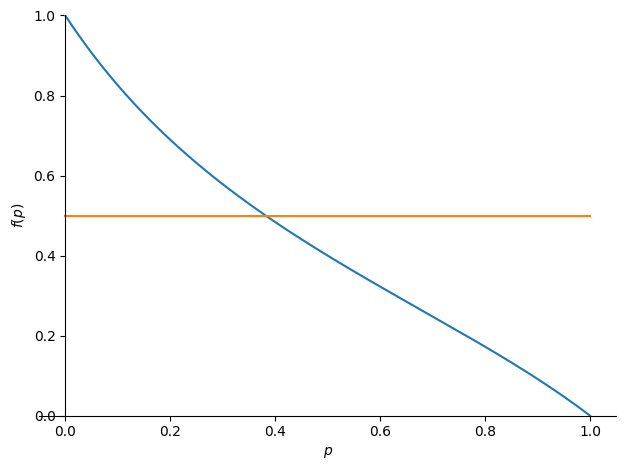

In [55]:
prawdPlot = plot(prawd, (p, 0, 1), axis_center=(0,0), ylim=(0,1), show=False)
halfPlot = plot(S(1)/2, (p, 0, 1), show=False)
prawdPlot.append(halfPlot[0])
prawdPlot.show()

In [56]:
half = solveset(prawd - S(1)/2, p, domain=Interval.open(0,1))
half

⎧3   √5⎫
⎨─ - ──⎬
⎩2   2 ⎭

In [57]:
t_k = symbols('t1:5')
t = linsolve((eye(4) - Q, ones(4)), t_k)
t = Matrix(list(t)[0])
t

⎡     3      2           ⎤
⎢  - p  + 2⋅p  + p - 3   ⎥
⎢────────────────────────⎥
⎢ 4      3      2        ⎥
⎢p  - 3⋅p  + 2⋅p  + p - 1⎥
⎢                        ⎥
⎢         p - 2          ⎥
⎢────────────────────────⎥
⎢ 4      3      2        ⎥
⎢p  - 3⋅p  + 2⋅p  + p - 1⎥
⎢                        ⎥
⎢    3      2            ⎥
⎢ - p  + 3⋅p  - 2⋅p - 1  ⎥
⎢────────────────────────⎥
⎢ 4      3      2        ⎥
⎢p  - 3⋅p  + 2⋅p  + p - 1⎥
⎢                        ⎥
⎢          -1            ⎥
⎢────────────────────────⎥
⎢ 4      3      2        ⎥
⎣p  - 3⋅p  + 2⋅p  + p - 1⎦

In [58]:
wartOczek = mu*t
wartOczek = simplify(wartOczek[0] + 2)
wartOczek

     3      2           
  - p  + 2⋅p  + p - 3   
────────────────────────
 4      3      2        
p  - 3⋅p  + 2⋅p  + p - 1

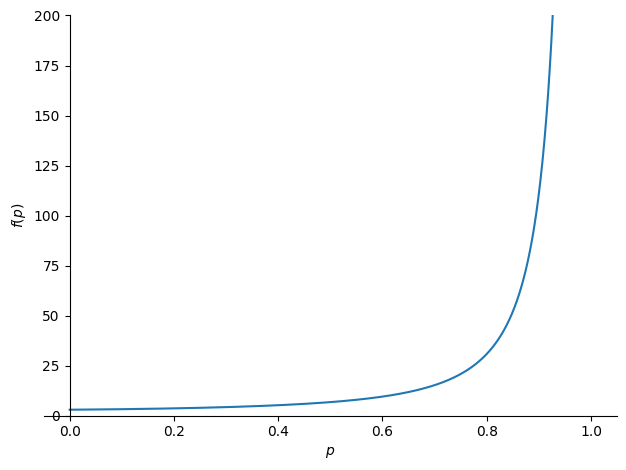

In [59]:
wartOczekBigPlot = plot(wartOczek, (p, 0, 1), ylim=(0, 200), axis_center=(0,0), show=False)
wartOczekBigPlot.show()

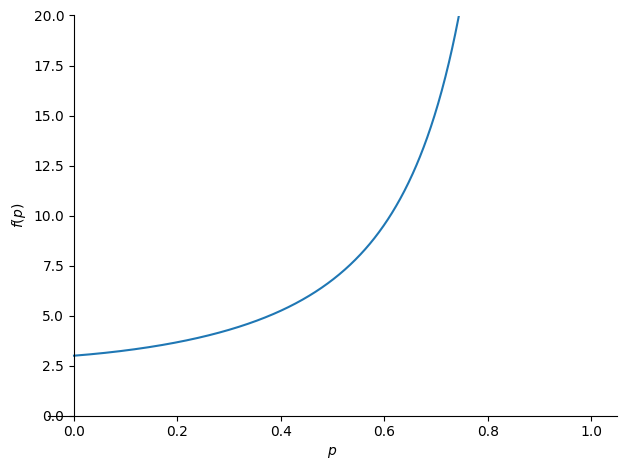

In [60]:
wartOczekSmallPlot = plot(wartOczek, (p, 0, 1), ylim=(0, 20), axis_center=(0,0), show=False)
wartOczekSmallPlot.show()